# Silage or Grain? Field-level corn harvest classification at USDA BARC

> **Submitted 2025 answer: `forecast/outputs/state_estimates_2025.csv`** (QuickStats format: US total and every state, corn for grain and corn for silage, acres harvested; 91 of the 92 rows in the judges' 2025 file, the one row without a prediction being the "OTHER STATES" grain aggregate, whose reference value is 0). It comes from the NASS-report forecast in `forecast/estimate_2025.py`, built only from reports released before the January 2026 Annual Summary. That forecast uses NASS reports only; this notebook documents the team's field-level satellite classifier at BARC and how it was validated.
>
> | Headline | Result | Source |
> | --- | --- | --- |
> | US corn for grain, 2025 | 90,047,000 vs NASS 90,948,000 acres (**-1.0%**) | `forecast/outputs/benchmark.json` |
> | US corn for silage, 2025 | 6,886,596 vs NASS 6,187,000 acres (**+11.3%**) | `forecast/outputs/benchmark.json` |
> | Maryland grain / silage, 2025 | 405,000 vs 410,000 (**-1.2%**); 37,595 vs 40,000 (**-6.0%**) | `forecast/outputs/benchmark.json` |
> | States within 10% of NASS | grain **33 of 41**, silage **23 of 48** | counted from the per-row errors in `forecast/outputs/benchmark.json` |
> | BARC field classifier, held out by field | **41 of 44** field-years right (10 of 12 silage, 1 false alarm in 32 grain); balanced accuracy **0.90**, about **0.87** after correcting for model selection | `baseline/outputs/metrics.json` |
>
> The satellite model applied statewide to Maryland 2025 over-calls silage by 39% (`baseline/outputs/estimate_2025/summary.json`), so it is a cross-check, not the submitted answer. The team summary is `SUBMISSION.md`.

**Question (USDA NASS):** was each corn field harvested as **silage** (chopped green, around dent stage, late summer) or **grain** (dried down and combined in fall)? Can we tell from public satellite data **before the January Annual Summary**, in a way a skeptic can check?

**Why it matters:** production = harvested acres x yield. Silage acres come out of grain acres, so an earlier silage estimate sharpens the corn production forecast.

**What this notebook shows, using only saved, versioned outputs (no live downloads):**
1. The data and its quality (clouds, rejected scenes, label counts).
2. The physical signal: silage drops from green to bare soil early; grain browns slowly.
3. A small, interpretable logistic regression, held out **by field**, against the always-Grain baseline.
4. How early in the season the call can be made.
5. A roll-up from fields to acres with an uncertainty interval, and the NASS context.

## Hypothesis
**H1 (timing and shape of greenness loss).** Silage corn is chopped green in late summer, so its NDVI falls sharply between two clear looks around late August to September and stays low. Grain corn dries down standing, so its NDVI fades gradually into October and November. Monthly NDVI medians from July to November should therefore separate the two classes, with September carrying most of the signal.

**H2 (post-harvest surface).** Grain harvest leaves more crop residue than silage harvest. *Not tested here:* the residue index (NDTI, from Sentinel-2 SWIR bands) was not extracted; see Limitations.

**How H1 is tested, and what would reject it**
| Test | Where | H1 is rejected if |
| --- | --- | --- |
| Silage and grain NDVI curves differ in late summer | Section 3 | the median curves overlap through September |
| A model on monthly NDVI beats always-Grain on held-out fields | Section 4 | balanced accuracy on held-out fields is at or below 0.5 |
| It still beats always-Grain on a whole held-out year | Section 4, "Holding out a whole year" | mean balanced accuracy over held-out years is at or below 0.5 |
| September is where the call is made | Section 6 and the convergence chart | skill does not rise once September NDVI is available |
| Better than the organizers' decline-date rule | Section 4, "Against the organizers' baseline" | the rule matches or beats the model on the same rows |

An early NDVI drop is treated as evidence about harvest timing, not as a label: labels come only from the BARC reference data.

## 1. Setup and source integrity
The notebook reads `baseline/outputs/` and the source GeoPackage. It first checks that the original source files are byte-identical to the recorded hashes.

In [1]:
import hashlib, json, math, os, sqlite3
from pathlib import Path
import numpy as np, pandas as pd, matplotlib.pyplot as plt

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / 'baseline' / 'outputs').exists())
OUT = ROOT / 'baseline' / 'outputs'
GPKG = ROOT / 'BARC_Corn.2021-2023.gpkg'
pd.set_option('display.precision', 3)

expected = json.loads((ROOT / 'baseline' / 'original_sha256.json').read_text())
integrity = {name: hashlib.sha256((ROOT / name).read_bytes()).hexdigest() == digest
             for name, digest in expected.items()}
print('project root:', ROOT)
assert all(integrity.values()), f'Source integrity failed: {integrity}'
integrity

project root: .


{'BARC_Corn.2021-2023.gpkg': True,
 'barc_fields_explorer.ipynb': True,
 'data_sources.md': True,
 'README.md': True,
 'sentinel-2_starter_notebook.ipynb': True}

## 2. Data and quality
- **Fields and labels:** 83 BARC field polygons (Beltsville, MD). Reference labels exist for 44 field-years on 34 fields; blank labels are unknown and never treated as Grain.
- **Imagery:** Sentinel-2 L2A (Microsoft Planetary Computer), July to November, per-field clear-pixel NDVI; scenes with too few clear pixels are rejected, not filled in.

In [2]:
audit = json.loads((OUT / 'audit.json').read_text())
metrics = json.loads((OUT / 'metrics.json').read_text())
labels = pd.DataFrame(audit['label_counts']).T
labels.loc['Total'] = labels.sum()
obs = pd.read_csv(OUT / 'observations.csv', parse_dates=['date'])
quality = pd.Series({
    'fields': audit['fields'], 'labeled field-years': metrics['labeled_field_years'],
    'scene observations': len(obs), 'accepted': int((obs.status == 'ok').sum()),
    'rejected (cloud / nodata)': metrics['cloud_or_nodata_rejections'], 'read errors': metrics['read_errors']})
display(labels); quality

,Grain,Silage,blank
2021,14,4,65
2022,3,4,76
2023,15,4,64
Total,32,12,205


fields                         83
labeled field-years            44
scene observations           1322
accepted                     1151
rejected (cloud / nodata)     171
read errors                     0
dtype: int64

### Data sources and reproducibility
| Source | What we use it for | Access | Query and parameters | Preprocessing and derived features |
| --- | --- | --- | --- | --- |
| BARC corn fields 2021-2023 (`BARC_Corn.2021-2023.gpkg`, layer `barc_silage_grain_corn20212023`) | Field polygons and Grain/Silage reference labels | Provided in the lab `04_Evaluation` folder; original byte hashes in `baseline/original_sha256.json` (checked in section 1) | 83 fields; labels `Corn_2021`, `Corn_2022`, `Corn_2023`; blanks are unknown | Reprojected from NAD83 / Maryland (ftUS) for imagery reads; EPSG:4326 for maps |
| Sentinel-2 Level-2A surface reflectance | NDVI time series per field | Microsoft Planetary Computer STAC, `https://planetarycomputer.microsoft.com/api/stac/v1`, collection `sentinel-2-l2a`, no key (`planetary_computer` URL signing) | Field geometry intersects; `{year}-07-01/{year}-11-30`; scene `eo:cloud_cover` < 40; bands B04, B08, SCL | Processing-baseline offset applied; SCL classes 4, 5, 6, 7 kept; a field-scene counts if at least 3 clear pixels and 20% of the field are clear; NDVI averaged over clear pixels; monthly medians July to November plus peak, peak day, late-season median and early-minus-late; model v2 adds four harvest-timing features from the same per-date series (date of a sustained decline, date and size of the largest drop, regrowth after it; `baseline/model_v2/features.py`). Every scene ID is in `baseline/outputs/observations.csv`; the query per field-year is cached in `baseline/cache/` |
| Sentinel-2 L2A `visual` (true color, 10 m) | Before/after image chips | Same catalog | Exactly the two scene IDs around each field-year's largest NDVI drop | Cropped around the field, outlined; provenance in `baseline/outputs/chips/index.json` |
| USDA NASS Quick Stats | State-level context only, never a label | `https://quickstats.nass.usda.gov/`; the 2025 judges' file is `data/reference/quickstats_2025_judges.csv` (download URL and SHA-256 in `quickstats_2025_judges.source.json`); the lab's 2012-2025 export via `QUICKSTATS_CSV` | Corn grain and silage acres harvested, state and national, domain TOTAL | Suppressed values such as `(D)` kept as missing, never zero |
| USDA Cropland Data Layer | Which unlabeled BARC field-years were corn (unlabeled calls only) | `https://nassgeodata.gmu.edu/webservice/nass_data_cache/byfips/CDL_{year}_24.tif` (Maryland) | Corn classes incl. double crops; at least 10 CDL pixels per field | Corn share per field-year; not used for training or scoring |

All derived numbers in this notebook come from versioned files in `baseline/outputs/`; the commands to regenerate them are under Reproduce.

In [3]:
obs_all = pd.read_csv(OUT / 'observations.csv', parse_dates=['date'])
prov = obs_all.groupby('year').agg(scenes=('item_id', 'nunique'), first=('date', 'min'), last=('date', 'max'),
                                   field_scenes=('item_id', 'size'), accepted=('status', lambda s: int((s == 'ok').sum())))
prov['first'] = prov['first'].dt.date; prov['last'] = prov['last'].dt.date
print('Sentinel-2 L2A scenes used, by year (every scene ID is in observations.csv):')
prov

Sentinel-2 L2A scenes used, by year (every scene ID is in observations.csv):


,scenes,first,last,field_scenes,accepted
year,,,,,
2021,27,2021-07-04,2021-11-26,388,361
2022,44,2022-07-04,2022-11-26,280,233
2023,43,2023-07-04,2023-11-19,654,557


## 3. The signal: what silage and grain look like from space
Median NDVI of accepted observations by day of year, with the middle 50% shaded. Silage fields fall to bare soil around late August to September; grain fields stay green longer and brown down gradually.

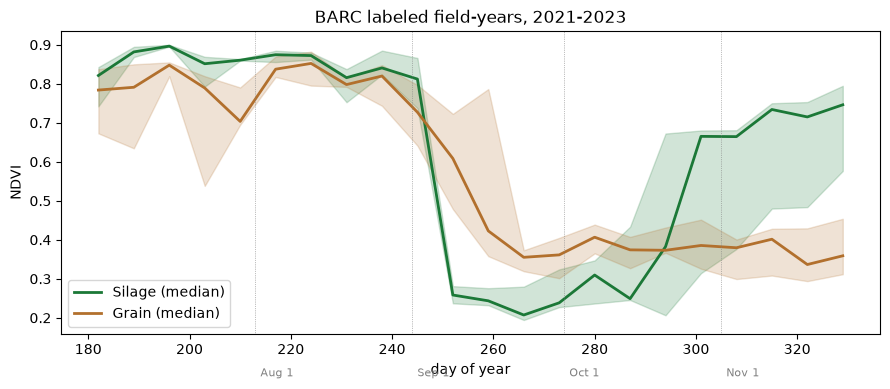

In [4]:
ok = obs[obs.status == 'ok'].merge(pd.read_csv(OUT / 'labels.csv'), on=['OBJECTID', 'year'])
ok['week'] = (ok.date.dt.day_of_year // 7) * 7
fig, ax = plt.subplots(figsize=(9, 4))
for lab, color in [('Silage', '#1b7837'), ('Grain', '#b2702d')]:
    g = ok[ok.label == lab].groupby('week').ndvi
    q = g.quantile([.25, .5, .75]).unstack()
    ax.plot(q.index, q[0.5], color=color, lw=2, label=f'{lab} (median)')
    ax.fill_between(q.index, q[0.25], q[0.75], color=color, alpha=.2)
for doy, name in [(213, 'Aug 1'), (244, 'Sep 1'), (274, 'Oct 1'), (305, 'Nov 1')]:
    ax.axvline(doy, color='grey', lw=.5, ls=':'); ax.text(doy + 1, 0.05, name, fontsize=8, color='grey')
ax.set(xlabel='day of year', ylabel='NDVI', title='BARC labeled field-years, 2021-2023'); ax.legend()
plt.tight_layout()

## 4. Model: small and interpretable
- **Features (13):** monthly median NDVI for July to November, peak NDVI and its day, September-onward median NDVI, early-minus-late NDVI, and four harvest-timing features from the same NDVI series: the date of a sustained decline, the date and size of the largest drop between clear looks, and the regrowth after the low point.
- **Model (v2):** median imputation, standard scaling, L1 logistic regression with C chosen by field-grouped inner cross-validation, threshold 0.5, all fitted inside each training fold only.
- **Validation:** 5-fold stratified **group** k-fold by field (`OBJECTID`), so every year of a field is held out together. Model v2 was picked by a pre-registered comparison on 20 other splits, not by tuning on these results; see Model v2 below.
- **Baseline:** always predict Grain. It scores well on accuracy because silage is rare, so we report **balanced accuracy, silage F1 and Brier score** instead.

### Model v2
The first submitted model (v1) used the nine NDVI features above with a plain logistic regression (C = 1). Model v2 adds the four timing features and an L1 penalty whose strength is chosen by inner cross-validation. It is candidate H of eight candidates whose features, settings and selection rule were written down and committed before any was scored, and it won on 20 fresh field-grouped splits (`baseline/model_v2/results.md`).

- **This split (seed 42):** v2 catches 10 of 12 silage field-years with 1 false alarm among 32 grain (balanced accuracy 0.90, Brier 0.065). v1 caught 7 of 12 with 1 false alarm (0.78, Brier 0.083).
- **How much to trust it:** this split was already seen when v2 was chosen, so its numbers are optimistic. Repeating the whole selection inside each training fold gives a balanced accuracy of about 0.87, against 0.80 for v1 on the same splits; that is the honest estimate. A field-level bootstrap 95% interval for the gain is 0.000 to 0.285, which touches zero: the gain rests on three or four silage field-years.
- **What stays v1:** v2 needs the full season (its timing features and November NDVI), so the mid-season calls in section 6 and the convergence chart still refit the v1 pipeline on the months available by each date.
- **Backup:** v1 code is unchanged; `HTH_MODEL_VERSION=v1` rebuilds every v1 output, and the v1 files are kept in `baseline/outputs/v1_backup/`.

In [5]:
cols = ['silage_precision', 'silage_recall', 'silage_f1', 'false_positive_rate', 'balanced_accuracy', 'brier_score']
print(metrics['protocol'])
pd.DataFrame({'Logistic regression': {k: metrics['logistic'][k] for k in cols},
              'Always Grain': {k: metrics['always_grain'][k] for k in cols}})

5-fold StratifiedGroupKFold, OBJECTID groups, shuffle=True, seed=42


,Logistic regression,Always Grain
silage_precision,0.909,0.000
silage_recall,0.833,0.000
silage_f1,0.870,0.000
false_positive_rate,0.031,0.000
balanced_accuracy,0.901,0.500
brier_score,0.065,0.273


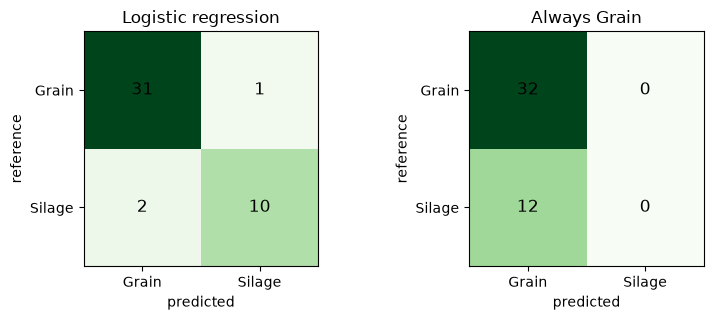

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(8, 3.3))
for ax, (name, key) in zip(axes, [('Logistic regression', 'logistic'), ('Always Grain', 'always_grain')]):
    cm = np.array(metrics[key]['confusion_matrix'])
    ax.imshow(cm, cmap='Greens', vmin=0)
    for i in range(2):
        for j in range(2): ax.text(j, i, cm[i, j], ha='center', va='center', fontsize=12)
    ax.set(xticks=[0, 1], yticks=[0, 1], xticklabels=['Grain', 'Silage'], yticklabels=['Grain', 'Silage'],
           xlabel='predicted', ylabel='reference', title=name)
plt.tight_layout()

### By year (same held-out predictions)

In [7]:
pred = pd.read_csv(OUT / 'heldout_predictions.csv')
assert pred.label.isin(['Grain', 'Silage']).all(), 'unknown reference labels'
assert pred.groupby('OBJECTID').fold.nunique().eq(1).all(), 'field crosses validation folds'
assert not pred.duplicated(['OBJECTID', 'year']).any(), 'duplicate field-years'
def year_scores(g):
    y, p = g.label == 'Silage', g.predicted_label == 'Silage'
    tp, fp, fn, tn = (y & p).sum(), (~y & p).sum(), (y & ~p).sum(), (~y & ~p).sum()
    rec, spec = tp / (tp + fn) if tp + fn else np.nan, tn / (tn + fp) if tn + fp else np.nan
    return pd.Series({'n': len(g), 'silage': int(y.sum()), 'caught': int(tp), 'false alarms': int(fp),
                      'balanced_accuracy': (rec + spec) / 2})
pred.groupby('year')[['label', 'predicted_label']].apply(year_scores)

,n,silage,caught,false alarms,balanced_accuracy
year,,,,,
2021,18.0,4.0,2.0,0.0,0.750
2022,7.0,4.0,4.0,1.0,0.833
2023,19.0,4.0,4.0,0.0,1.000


### Precision and recall for both classes, with Wilson 95% intervals
With 12 silage field-years, intervals are wide; we show them rather than a single number.

In [8]:
def wilson(k, n, z=1.96):
    if n == 0: return (np.nan, np.nan)
    p = k / n; c = (p + z*z/(2*n)) / (1 + z*z/n); h = z * math.sqrt(p*(1-p)/n + z*z/(4*n*n)) / (1 + z*z/n)
    return (max(0, c - h), min(1, c + h))
y, p = pred.label, pred.predicted_label
rows = []
for cls in ['Grain', 'Silage']:
    tp = int(((y == cls) & (p == cls)).sum()); npred = int((p == cls).sum()); nref = int((y == cls).sum())
    for metric, k, n in [('precision', tp, npred), ('recall', tp, nref)]:
        lo, hi = wilson(k, n)
        rows.append({'class': cls, 'metric': metric, 'value': k / n if n else np.nan, 'k/n': f'{k}/{n}', '95% low': lo, '95% high': hi})
pd.DataFrame(rows).set_index(['class', 'metric'])

value    k/n  95% low  95% high
class  metric                                    
Grain  precision  0.939  31/33    0.804     0.983
       recall     0.969  31/32    0.843     0.994
Silage precision  0.909  10/11    0.623     0.984
       recall     0.833  10/12    0.552     0.953

### Against the organizers' baseline: date of sustained NDVI decline
The lab names a transparent rule to beat: call a field Silage when its NDVI shows a sustained decline early enough. The rule's date threshold is fitted on training fields only, on the same field folds, and scored on the same 44 field-years as the model (`baseline/outputs/decline_rule/metrics.json`).

In [9]:
rule = json.loads((OUT / 'decline_rule' / 'metrics.json').read_text())
assert rule['evaluated_field_years'] == len(pred), 'decline rule scored on different rows'
def row(name, m):
    (tn, fp), (fn, tp) = m['confusion_matrix']
    return {'model': name, 'balanced_accuracy': m['balanced_accuracy'], 'silage caught': f'{tp}/{tp + fn}',
            'false alarms (of grain)': f'{fp}/{fp + tn}', 'silage precision': m['silage_precision']}
print(rule['protocol'])
display(pd.DataFrame([row('Logistic regression (ours)', rule['logistic_same_rows']),
                      row("Organizers' decline-date rule", rule['decline_rule']),
                      row('Always Grain', rule['always_grain_same_rows'])]).set_index('model').round(3))
pd.DataFrame({y: {k: round(v['balanced_accuracy'], 3) for k, v in r.items()} for y, r in rule['by_year'].items()}).T.rename_axis('year')

Saved field-grouped folds; threshold fitted on training fields only; DROP fixed at 0.25 before any result was computed


,balanced_accuracy,silage caught,false alarms (of grain),silage precision
model,,,,
Logistic regression (ours),0.901,10/12,1/32,0.909
Organizers' decline-date rule,0.693,11/12,17/32,0.393
Always Grain,0.500,0/12,0/32,0.000


,decline_rule,logistic
year,,
2021,0.571,0.750
2022,0.833,0.833
2023,0.742,1.000


The decline rule finds almost every silage field but also flags about half the grain fields, because grain fields lose greenness too, just later and more slowly. The model's features (monthly NDVI plus the timing and size of the largest drop) separate a sharp late-summer cut from a gradual fall dry-down, which keeps false alarms low. With 12 silage field-years, a difference of one or two fields is within noise.

### Holding out a whole year
The main results hold out fields. The challenge also asks for a held-out year: train on two seasons, test on the third. **Plain**: train on the other two years. **Strict**: also drop, from training, every field that appears in the test year, so no field is ever on both sides. Same model as the main results (model v2): its C is chosen by inner cross-validation on the training rows only, and nothing else is tuned.

In [10]:
try:
    from sklearn.impute import SimpleImputer
    from sklearn.linear_model import LogisticRegression
    from sklearn.pipeline import make_pipeline
    from sklearn.preprocessing import StandardScaler
    HAVE_SK = True
except ImportError:
    HAVE_SK = False; print('scikit-learn not installed: pip install scikit-learn to run this section')
if HAVE_SK:
    import sys
    sys.path.insert(0, str(ROOT / 'baseline'))
    import model_version  # the saved model: v2 (NDVI + timing features, L1) or v1 (NDVI, C = 1)
    VERSION = metrics.get('model_version', 'v1')
    feats_ = metrics['features']
    def scores(y, hat):
        tp = int((y & hat).sum()); fn = int((y & ~hat).sum()); fp = int((~y & hat).sum()); tn = int((~y & ~hat).sum())
        rec = tp / (tp + fn) if tp + fn else np.nan; spec = tn / (tn + fp) if tn + fp else np.nan
        return {'silage caught': f'{tp}/{tp + fn}', 'false alarms': f'{fp}/{fp + tn}', 'balanced_accuracy': (rec + spec) / 2}
    rows_ = []
    for test_year in sorted(pred.year.unique()):
        test = pred[pred.year == test_year]
        for mode in ('plain', 'strict'):
            train = pred[pred.year != test_year]
            if mode == 'strict':
                train = train[~train.OBJECTID.isin(test.OBJECTID)]
            if train.label.nunique() < 2:
                rows_.append({'held-out year': test_year, 'split': mode, 'train rows': len(train), 'note': 'one class only'}); continue
            m = model_version.build_model(VERSION)
            m.fit(train[feats_], train.label == 'Silage', train.OBJECTID.to_numpy())
            hat = m.predict_proba(test[feats_])[:, 1] >= 0.5
            rows_.append({'held-out year': test_year, 'split': mode, 'train rows': len(train),
                          'train silage': int((train.label == 'Silage').sum()), 'test rows': len(test),
                          **scores((test.label == 'Silage').to_numpy(), hat)})
    year_out = pd.DataFrame(rows_).set_index(['held-out year', 'split'])
    display(year_out.round(3))
    for mode in ('plain', 'strict'):
        sub = year_out.xs(mode, level='split')
        print(f'{mode}: mean balanced accuracy over held-out years = {sub.balanced_accuracy.mean():.3f}'
              ' (always Grain = 0.500)')

train rows  train silage  test rows silage caught  \
held-out year split                                                       
2021          plain           26             8         18           3/4   
              strict          18             8         18           3/4   
2022          plain           37             8          7           4/4   
              strict          33             8          7           4/4   
2023          plain           25             8         19           4/4   
              strict          15             7         19           1/4   

                     false alarms  balanced_accuracy  
held-out year split                                   
2021          plain          2/14              0.804  
              strict         1/14              0.839  
2022          plain           1/3              0.833  
              strict          1/3              0.833  
2023          plain          0/15              1.000  
              strict         0/15              0.625

plain: mean balanced accuracy over held-out years = 0.879 (always Grain = 0.500)
strict: mean balanced accuracy over held-out years = 0.766 (always Grain = 0.500)


Each held-out year has only 4 silage field-years, so one field moves recall by 25 points. Read this table for direction (does the model still beat always-Grain on an unseen season?), not for precise values.

### Holding out a whole farm (spatially separated group)
BARC fields belong to separate farms. Here each farm is held out in turn: train on every other farm, test on that one. Same model as the main results (model v2): its C is chosen by inner cross-validation on the training rows only, and nothing else is tuned.

In [11]:
with sqlite3.connect(f'file:{GPKG}?mode=ro', uri=True) as db:
    farms = pd.read_sql('SELECT OBJECTID, FARM FROM barc_silage_grain_corn20212023', db)
pf = pred.merge(farms, on='OBJECTID', how='left')
assert pf.FARM.notna().all(), 'field without a farm'
display(pf.groupby('FARM').label.value_counts().unstack(fill_value=0).rename_axis('farm'))
if HAVE_SK:
    rows_ = []
    for farm, test in pf.groupby('FARM'):
        train = pf[pf.FARM != farm]
        m = model_version.build_model(VERSION)  # the saved model, as in the year hold-out above
        m.fit(train[feats_], train.label == 'Silage', train.OBJECTID.to_numpy())
        hat = m.predict_proba(test[feats_])[:, 1] >= 0.5
        rows_.append({'held-out farm': farm, 'train silage': int((train.label == 'Silage').sum()), 'test rows': len(test),
                      **scores((test.label == 'Silage').to_numpy(), hat)})
    display(pd.DataFrame(rows_).set_index('held-out farm').round(3))

label,Grain,Silage
farm,,
APU,4,0
Central Farm,14,11
East Farm,11,1
Linkage Farm,1,0
North Farm,2,0


<site-packages>\sklearn\model_selection\_split.py:1036: UserWarning: The least populated class in y has only 1 members, which is less than n_splits=4.
  warnings.warn(


,train silage,test rows,silage caught,false alarms,balanced_accuracy
held-out farm,,,,,
APU,12,4,0/0,2/4,NaN
Central Farm,1,25,0/11,0/14,0.5
East Farm,11,12,1/1,0/11,1.0
Linkage Farm,12,1,0/0,0/1,NaN
North Farm,12,2,0/0,0/2,NaN


**Reading it honestly.** 11 of the 12 silage field-years are on Central Farm. Holding it out leaves one silage example for training, and the model then catches 0 of 11 silage fields there (balanced accuracy 0.5, the same as always-Grain). East Farm's single silage field is caught with no false alarms on its 11 grain fields; APU shows 2 false alarms on 4 grain fields. So BARC cannot show that silage detection transfers to a new farm: spatial transfer is an open limitation, not a result, and needs labeled silage fields from other farms or counties.

## 5. Explainable to a skeptic: the evidence behind each call
Feature values by reference label, and the NDVI curves of the silage fields the model **missed**, so reviewers can see why.

label,Grain,Silage
median by label,,
ndvi_08,0.831,0.864
ndvi_09,0.641,0.264
ndvi_10,0.364,0.276
peak_doy,206.500,197.500
late_ndvi,0.404,0.481
early_minus_late,0.427,0.216


,OBJECTID,year,valid_dates,silage_probability,ndvi_09,late_ndvi
7,291,2021,21,4.480e-01,0.215,0.306
9,327,2021,12,4.271e-05,0.499,0.495


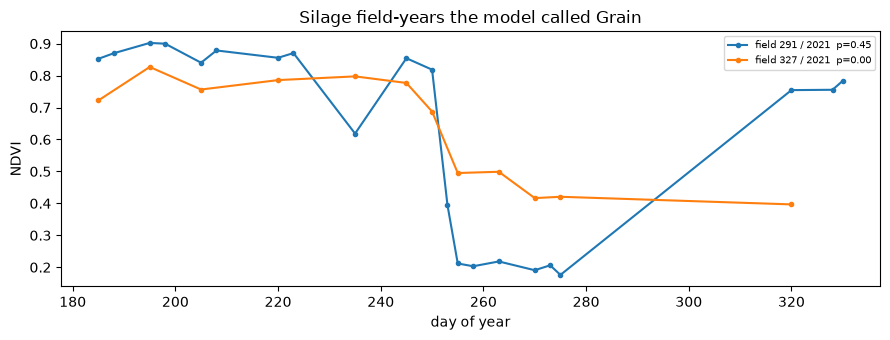

In [12]:
feat = pd.read_csv(OUT / 'features.csv')
show = ['ndvi_08', 'ndvi_09', 'ndvi_10', 'peak_doy', 'late_ndvi', 'early_minus_late']
display(feat.groupby('label')[show].median().T.rename_axis('median by label'))
missed = pred[(pred.label == 'Silage') & (pred.predicted_label == 'Grain')]
fig, ax = plt.subplots(figsize=(9, 3.5))
for _, r in missed.iterrows():
    g = ok[(ok.OBJECTID == r.OBJECTID) & (ok.year == r.year)].sort_values('date')
    ax.plot(g.date.dt.day_of_year, g.ndvi, marker='o', ms=3, label=f'field {r.OBJECTID} / {r.year}  p={r.silage_probability:.2f}')
ax.set(xlabel='day of year', ylabel='NDVI', title='Silage field-years the model called Grain'); ax.legend(fontsize=7)
plt.tight_layout()
missed[['OBJECTID', 'year', 'valid_dates', 'silage_probability', 'ndvi_09', 'late_ndvi']]

## 6. How early can we call it?
Before Nov 30 we refit the v1 pipeline (nine-feature logistic regression, C = 1) on the **same saved field folds**, using only the monthly medians complete by each date (they are complete at month end). Model v2 needs the full season, so it appears only in the last row, next to a full-season v1 refit for comparison. Nothing is tuned on held-out results.

In [13]:
try:
    from sklearn.impute import SimpleImputer
    from sklearn.linear_model import LogisticRegression
    from sklearn.metrics import balanced_accuracy_score, brier_score_loss, f1_score
    from sklearn.pipeline import make_pipeline
    from sklearn.preprocessing import StandardScaler
except ImportError:
    print('scikit-learn not installed: pip install scikit-learn to run this section'); SK = False
else:
    SK = True

CUTOFFS = {'Aug 31': ['ndvi_07', 'ndvi_08'],
           'Sep 30': ['ndvi_07', 'ndvi_08', 'ndvi_09'],
           'Oct 31': ['ndvi_07', 'ndvi_08', 'ndvi_09', 'ndvi_10'],
           'Nov 30 (full season, saved model)': metrics['features']}
V2 = metrics.get('model_version') == 'v2'
TIMING = ['decline_doy', 'drop_doy', 'drop_size', 'regrowth']
if V2:  # model v2 needs the full season; earlier rows (and a v1 full-season row) refit the v1 pipeline
    CUTOFFS = {**{k: v for k, v in CUTOFFS.items() if not k.startswith('Nov')},
               'Nov 30 (v1, nine NDVI features)': [f for f in metrics['features'] if f not in TIMING],
               'Nov 30 (full season, saved model v2)': metrics['features']}
if SK:
    d = pred.copy(); y = (d.label == 'Silage').astype(int).to_numpy()
    rows = []
    for name, cols_ in CUTOFFS.items():
        prob = np.zeros(len(d))
        if V2 and 'saved model v2' in name:
            prob = d.silage_probability.to_numpy()  # the saved held-out probabilities of model v2
        else:
            for fold in sorted(d.fold.unique()):
                tr, te = d.fold != fold, d.fold == fold
                m = make_pipeline(SimpleImputer(strategy='median', keep_empty_features=True), StandardScaler(),
                                  LogisticRegression(C=1.0, max_iter=2000, random_state=42))
                m.fit(d.loc[tr, cols_], y[tr]); prob[te.to_numpy()] = m.predict_proba(d.loc[te, cols_])[:, 1]
        hat = (prob >= 0.5).astype(int)
        rows.append({'as of': name, 'features': len(cols_), 'balanced_accuracy': balanced_accuracy_score(y, hat),
                     'silage_f1': f1_score(y, hat, zero_division=0), 'brier': brier_score_loss(y, prob),
                     'silage caught': f'{int((hat & y).sum())}/{int(y.sum())}', 'false alarms': int((hat & (1 - y)).sum())})
    early = pd.DataFrame(rows).set_index('as of')
    check = (abs(early.iloc[-1].balanced_accuracy - metrics['logistic']['balanced_accuracy']) < 1e-9
             and abs(early.iloc[-1].brier - metrics['logistic']['brier_score']) < 1e-9)
    if V2:  # the v1 full-season refit must reproduce v1 on the same split
        v1_row = early.loc['Nov 30 (v1, nine NDVI features)']
        check = check and all(abs(v1_row[a] - metrics['v1_logistic_same_split'][b]) < 1e-9
                              for a, b in [('balanced_accuracy', 'balanced_accuracy'), ('brier', 'brier_score')])
    print('full-season refit reproduces saved metrics:', check)
    assert check, 'Full-season refit differs from saved evaluation'
    display(early)

full-season refit reproduces saved metrics: True


,features,balanced_accuracy,silage_f1,brier,silage caught,false alarms
as of,,,,,,
Aug 31,2,0.594,0.353,0.156,3/12,2
Sep 30,3,0.818,0.762,0.116,8/12,1
Oct 31,4,0.776,0.700,0.121,7/12,1
"Nov 30 (v1, nine NDVI features)",9,0.776,0.700,0.083,7/12,1
"Nov 30 (full season, saved model v2)",13,0.901,0.870,0.065,10/12,1


Every row is months before the January Annual Summary. The table shows the trade-off between calling early and calling accurately.

## 7. Roll-up: fields to acres, with uncertainty
Expected silage acres = sum of p(silage) x field acres; the 95% interval and CV% (as NASS prints it) treat field-years as independent. The **adjusted** column applies the misclassification correction (q - FPR)/(TPR - FPR), with acre-weighted error rates from the other years only. **Scope:** only the 44 labeled field-years, so we can compare against reference acres.

In [14]:
with sqlite3.connect(f'file:{GPKG}?mode=ro', uri=True) as db:
    acres = pd.read_sql('SELECT OBJECTID, ACRES FROM barc_silage_grain_corn20212023', db)
r = pred.merge(acres, on='OBJECTID', how='left')
assert r.ACRES.notna().all(), 'missing acres for some field-years'
def rates(df):  # acre-weighted, to correct an acre-weighted share (same as the API)
    s, g = df[df.label == 'Silage'], df[df.label == 'Grain']
    return (s.ACRES[s.predicted_label == 'Silage'].sum() / s.ACRES.sum(),
            g.ACRES[g.predicted_label == 'Silage'].sum() / g.ACRES.sum())
def rollup(g):
    p, a = g.silage_probability, g.ACRES
    exp, sd = (p * a).sum(), math.sqrt((a**2 * p * (1 - p)).sum())
    q = a[g.predicted_label == 'Silage'].sum() / a.sum()
    tpr, fpr = rates(r[r.year != g.name])   # error rates from the OTHER years only
    adj = min(1, max(0, (q - fpr) / (tpr - fpr))) if tpr > fpr else np.nan
    return pd.Series({'field-years': len(g), 'total acres': a.sum(),
        'reference silage acres': a[g.label == 'Silage'].sum(),
        'expected silage acres': exp, '95% low': max(0, exp - 1.96 * sd), '95% high': exp + 1.96 * sd,
        'CV %': 100 * sd / exp, 'adjusted silage acres': adj * a.sum()})
roll = r.groupby('year')[['silage_probability', 'ACRES', 'label', 'predicted_label']].apply(rollup)
roll['reference inside 95%'] = roll['reference silage acres'].between(roll['95% low'], roll['95% high'])
roll.round(1)

,field-years,total acres,reference silage acres,expected silage acres,95% low,95% high,CV %,adjusted silage acres,reference inside 95%
year,,,,,,,,,
2021,18.0,321.6,76.5,79.3,24.8,133.8,35.1,12.9,True
2022,7.0,110.4,74.4,68.5,32.3,104.8,27.0,110.4,True
2023,19.0,304.2,108.0,103.8,54.3,153.3,24.3,132.1,True


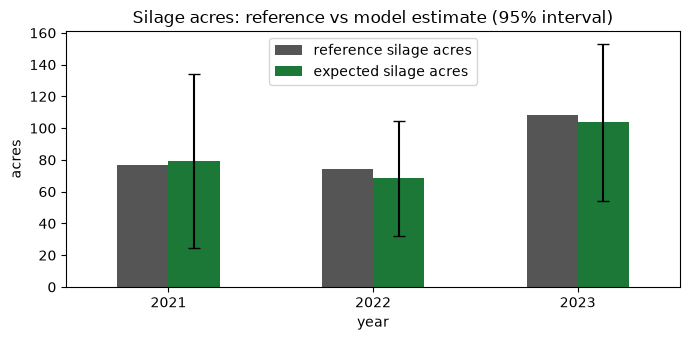

In [15]:
ax = roll[['reference silage acres', 'expected silage acres']].plot.bar(figsize=(7, 3.5), color=['#555', '#1b7837'], rot=0)
ax.errorbar(np.arange(len(roll)) + 0.125, roll['expected silage acres'],
            yerr=[roll['expected silage acres'] - roll['95% low'], roll['95% high'] - roll['expected silage acres']],
            fmt='none', color='black', capsize=4)
ax.set(ylabel='acres', title='Silage acres: reference vs model estimate (95% interval)'); plt.tight_layout()

### Convergence through the season (Justin's ask)
NASS releases monthly forecasts around the 12th. We re-run the estimate **as of each release date**, using only the monthly NDVI medians complete by then (the v1 pipeline, same saved field folds). The January row is the saved full-season prediction of model v2, not a NASS estimate. Neither convergence toward reference acres nor narrower intervals is guaranteed.

,,features,expected,low,high,CV %,reference,balanced_accuracy
year,as of,,,,,,,
2021,08-12,1,88.23,18.36,158.10,40.40,76.49,0.50
2022,08-12,1,39.66,0.00,82.07,54.56,74.44,0.50
2023,08-12,1,83.32,16.96,149.68,40.64,107.98,0.50
2021,09-12,2,73.98,8.54,139.42,45.13,76.49,0.50
2022,09-12,2,43.80,1.07,86.54,49.77,74.44,0.33
2023,09-12,2,99.58,29.62,169.54,35.84,107.98,0.84
2021,10-12,3,93.04,27.10,158.98,36.16,76.49,0.88
2022,10-12,3,73.71,40.13,107.28,23.24,74.44,0.83
2023,10-12,3,68.99,9.19,128.79,44.23,107.98,0.62


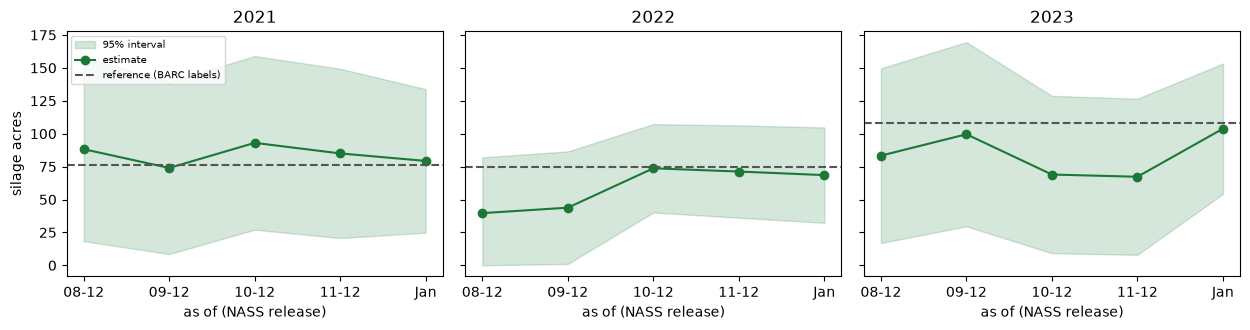

In [16]:
RELEASES = ['08-12', '09-12', '10-12', '11-12']
YEARS = sorted(pred.year.unique())
assert (r.OBJECTID.values == pred.OBJECTID.values).all()  # same row order as the folds
MONTH_END = {'ndvi_07': '07-31', 'ndvi_08': '08-31', 'ndvi_09': '09-30', 'ndvi_10': '10-31', 'ndvi_11': '11-30'}
def asof_probs(cols_):
    d = pred.copy(); yv = (d.label == 'Silage').astype(int).to_numpy(); prob = np.zeros(len(d))
    for fold in sorted(d.fold.unique()):
        tr, te = (d.fold != fold).to_numpy(), (d.fold == fold).to_numpy()
        m = make_pipeline(SimpleImputer(strategy='median', keep_empty_features=True), StandardScaler(),
                          LogisticRegression(C=1.0, max_iter=2000, random_state=42))
        m.fit(d.loc[tr, cols_], yv[tr]); prob[te] = m.predict_proba(d.loc[te, cols_])[:, 1]
    return prob
conv = []
if SK:
    for md_ in RELEASES + ['Jan']:
        cols_ = metrics['features'] if md_ == 'Jan' else [f for f, end in MONTH_END.items() if end <= md_]
        if not cols_:
            continue
        rr = r.copy()
        rr['p'] = rr.silage_probability if md_ == 'Jan' else asof_probs(cols_)
        rr['hat'] = np.where(rr.p >= 0.5, 'Silage', 'Grain')
        for yr, g in rr.groupby('year'):
            exp, sd = (g.p * g.ACRES).sum(), math.sqrt((g.ACRES**2 * g.p * (1 - g.p)).sum())
            conv.append({'year': yr, 'as of': md_, 'features': len(cols_), 'expected': exp,
                         'low': max(0, exp - 1.96 * sd), 'high': exp + 1.96 * sd, 'CV %': 100 * sd / exp,
                         'reference': g.ACRES[g.label == 'Silage'].sum(),
                         'balanced_accuracy': balanced_accuracy_score(g.label == 'Silage', g.hat == 'Silage')})
    conv = pd.DataFrame(conv)
    fig, axes = plt.subplots(1, len(YEARS), figsize=(4.2 * len(YEARS), 3.4), sharey=True)
    for ax, yr in zip(axes, YEARS):
        c = conv[conv.year == yr]; x = np.arange(len(c))
        ax.fill_between(x, c.low, c.high, color='#1b7837', alpha=.18, label='95% interval')
        ax.plot(x, c.expected, 'o-', color='#1b7837', label='estimate')
        ax.axhline(c.reference.iloc[0], color='#555', ls='--', label='reference (BARC labels)')
        ax.set_xticks(x, c['as of']); ax.set_title(str(yr)); ax.set_xlabel('as of (NASS release)')
    axes[0].set_ylabel('silage acres'); axes[0].legend(fontsize=7, loc='upper left'); plt.tight_layout()
    display(conv.set_index(['year', 'as of']).round(2))
else:
    print('scikit-learn needed for the convergence run')

**Reading the chart honestly.**
- **Scores improve by October.** Balanced accuracy is 0.5 (no better than always-Grain) on Aug 12 in every year; by Oct 12 it is 0.62 to 0.88. September NDVI improves scores in all three years here; August NDVI already separates some 2023 fields, while the Sep 12 score in 2022 is below chance.
- **Early acre estimates are not skill.** In August the probabilities fall back toward the base rate, so the acres can land near the reference without any field being identified. Judge the early dates by balanced accuracy, not by the acre line.
- **The interval does not narrow consistently.** CV ranges from about 23 to 55%; each year has only 7 to 19 labeled field-years. In 2022 it falls from 55% in August to 23% in October, then rises to 27% in the full-season row. These intervals condition on model probabilities and omit model and spatial dependence uncertainty.
- The reference line sits inside the 95% interval at every date in every year.

**What worked, what didn't:** the reference acres fall inside the 95% interval every year, so the expected-value estimate is the headline. The misclassification adjustment is unstable here because its error rates rest on about 8 silage field-years; it would matter more on a larger labeled set.

### Where the uncertainty comes from, and how it converges
The interval is wide because each year has only 7 to 19 labeled fields: the total is a sum of a few weighted coin flips. Most of that width sits in a handful of large fields the model is unsure about. Below: each field's share of the variance (acres² × p × (1 − p)), then a **what-if**: an analyst verifies only the most uncertain fields (from imagery, a farm call or an FSA record) and the rest keep the model's probabilities. The checked fields take their BARC reference label here, so this shows the value of checking, not a model result.

In [17]:
r_ = r.assign(var=r.ACRES**2 * r.silage_probability * (1 - r.silage_probability))
def total(g, p):
    e = (p * g.ACRES).sum(); sd = math.sqrt((g.ACRES**2 * p * (1 - p)).sum())
    return e, max(0, e - 1.96 * sd), e + 1.96 * sd, 100 * sd / e if e else float('nan')
drivers, checks = [], []
for yr, g in r_.groupby('year'):
    g = g.sort_values('var', ascending=False)
    share = g['var'].cumsum() / g['var'].sum(); k = int((share < 0.5).sum()) + 1
    drivers.append({'year': yr, 'fields': len(g), 'fields giving half the variance': k,
                    'their share': round(float(share.iloc[k - 1]), 2),
                    'which': ', '.join(f'#{o} ({a:.0f} ac, p={p:.2f})' for o, a, p in
                                       g.head(k)[['OBJECTID', 'ACRES', 'silage_probability']].itertuples(index=False))})
    ref = g.ACRES[g.label == 'Silage'].sum()
    for n in (0, 1, 3, 5):
        p = g.silage_probability.copy()
        top = g.index[:n]; p[top] = (g.loc[top, 'label'] == 'Silage').astype(float)
        e, lo, hi, cv = total(g, p)
        checks.append({'year': yr, 'fields checked': n, 'estimate': e, '95% low': lo, '95% high': hi,
                       'CV %': cv, 'reference acres': ref, 'reference inside 95%': lo <= ref <= hi})
display(pd.DataFrame(drivers).set_index('year'))
pd.DataFrame(checks).set_index(['year', 'fields checked']).round(1)

,fields,fields giving half the variance,their share,which
year,,,,
2021,18,2,0.57,"#263 (33 ac, p=0.35), #301 (41 ac, p=0.13)"
2022,7,1,0.63,"#252 (30 ac, p=0.55)"
2023,19,3,0.65,"#254 (27 ac, p=0.65), #323 (25 ac, p=0.66), #2..."


estimate  95% low  95% high  CV %  reference acres  \
year fields checked                                                       
2021 0                   79.3     24.8     133.8  35.1             76.5   
     1                   67.9     22.7     113.0  34.0             76.5   
     3                   72.2     40.7     103.6  22.2             76.5   
     5                   59.7     36.3      83.2  20.0             76.5   
2022 0                   68.5     32.3     104.8  27.0             74.4   
     1                   81.7     59.7     103.7  13.7             74.4   
     3                   75.5     65.6      85.4   6.7             74.4   
     5                   74.3     71.6      77.0   1.9             74.4   
2023 0                  103.8     54.3     153.3  24.3            108.0   
     1                  113.1     70.5     155.8  19.2            108.0   
     3                  117.0     87.8     146.2  12.7            108.0   
     5                  117.5     96.1     139.0   9.3            108.0   

                     reference inside 95%  
year fields checked                        
2021 0                               True  
     1                               True  
     3                               True  
     5                               True  
2022 0                               True  
     1                               True  
     3                               True  
     5                               True  
2023 0                               True  
     1                               True  
     3                               True  
     5                               True

Checking the few flagged fields narrows the interval. In 2022, verifying 3 of 7 fields gives 75.5 acres at about 7% CV against 74.4 true. In years with more fields a narrower interval is not always a more accurate one: in 2021 the estimate drifts from 79.3 to 59.7 (reference 76.5) and in 2023 it overshoots to 117.5 (reference 108.0) while the CV falls, so those years need more checks before the estimate settles. The model's own interval stays honest about what it does not know; convergence comes from targeted human verification, which is also how the agent's Verifier is designed (it flags borderline and thin-imagery fields for review).

### NASS context
BARC is a small research farm, so its acres are not comparable to Maryland totals. Below are filtered Maryland state-level NASS rows and the BARC model's silage share for context. Set `QUICKSTATS_CSV` to the team's QuickStats export. Suppressed values remain null and are never zeroed. In the saved run below `QUICKSTATS_CSV` was not set, because the lab's multi-year QuickStats export is not in this repository, so the cell reports the NASS rows as unavailable; the BARC silage share still prints.

In [18]:
import sys
sys.path.insert(0, str(ROOT / 'backend'))
from app import artifacts
try:
    qs = [q.model_dump() for year in sorted(pred.year.unique())
          for use in ['grain', 'silage']
          for q in artifacts.read_quickstats('MARYLAND', int(year), use, 'STATE')]
    display(pd.DataFrame(qs))
except artifacts.ArtifactUnavailable as exc:
    print('NASS context unavailable:', exc)
print('BARC modelled silage share of labeled corn acres:')
(roll['expected silage acres'] / roll['total acres']).round(3)

NASS context unavailable: QUICKSTATS_CSV is not set. Point it at a NASS QuickStats CSV, for example data/reference/quickstats_2025_judges.csv (2025 judge totals).
BARC modelled silage share of labeled corn acres:


year
2021    0.247
2022    0.621
2023    0.341
dtype: float64

#### Should the model use Maryland's silage share as a prior?
NASS puts Maryland's silage share of harvested corn at about 6 to 12% of acres since 2013 (7.8% in 2021, 6.4% in 2023), well below the 27% silage share in the BARC labels. BARC has a dairy herd, so a higher silage share is expected there. The cell below tests whether shifting every held-out probability to a 7.5% prior (a constant change in log-odds) helps. It does not. It catches fewer silage fields and falls far short of the reference acres, so the model keeps the BARC base rate. QuickStats stays context only, never field labels.

In [19]:
import numpy as np
P = artifacts.read_predictions()
train_prev = np.mean([p.reference_label == 'Silage' for p in P])
logit = lambda x: np.log(x / (1 - x))
shift = logit(0.075) - logit(train_prev)

def with_prior(ps):
    out = []
    for p in ps:
        q = float(1 / (1 + np.exp(-(logit(np.clip(p.silage_probability, 1e-9, 1 - 1e-9)) + shift))))
        out.append(p.model_copy(update={'silage_probability': q, 'predicted_label': 'Silage' if q >= 0.5 else 'Grain'}))
    return out

def summary(ps, name):
    sil = [p for p in ps if p.reference_label == 'Silage']; gr = [p for p in ps if p.reference_label == 'Grain']
    rec = np.mean([p.predicted_label == 'Silage' for p in sil]); spec = np.mean([p.predicted_label == 'Grain' for p in gr])
    r = artifacts.compute_rollup(ps)
    return {'model': name, 'balanced accuracy': round((rec + spec) / 2, 3), 'silage recall': f"{int(rec * len(sil))}/{len(sil)}",
            **{f"{y.year} expected acres (ref {y.reference_silage_acres})": y.expected_silage_acres for y in r.years}}

print(f'BARC label silage share {train_prev:.3f}; Maryland prior 0.075; log-odds shift {shift:.2f}')
pd.DataFrame([summary(P, 'BARC base rate (used)'), summary(with_prior(P), 'Maryland 7.5% prior')]).set_index('model')

BARC label silage share 0.273; Maryland prior 0.075; log-odds shift -1.53


,balanced accuracy,silage recall,2021 expected acres (ref 76.49),2022 expected acres (ref 74.44),2023 expected acres (ref 107.98)
model,,,,,
BARC base rate (used),0.901,10/12,79.32,68.54,103.78
Maryland 7.5% prior,0.750,6/12,43.71,45.81,66.60


## 8. Agent trace
Set `AGENT_RUN_ID` to the specific run to inspect. Only that run's logged steps are shown; the notebook does not select another run automatically. The agent implementation is optional.

In [20]:
from app import tools as backend_tools
run_id = os.environ.get('AGENT_RUN_ID')
if run_id:
    steps = backend_tools.read_trace(run_id)
    display(pd.DataFrame(steps).tail(25))
else:
    print('Set AGENT_RUN_ID to inspect a trace from', backend_tools.TRACES_DIR)

Set AGENT_RUN_ID to inspect a trace from agent_runs\traces


## 9. Limitations
- 44 labeled field-years on 34 fields at one research farm. Per-year silage counts are 4, so metrics have wide uncertainty.
- Grouping by field prevents same-field leakage, but nearby fields share imagery and management; this does not show transfer to other regions or future years.
- Clouds can hide the cut week; rejected scenes are reported, never filled in.
- Early harvest is not always silage elsewhere (e.g., Texas summer grain); thresholds learned here reflect Maryland timing.
- Double crops are not modelled separately.
- Spatial transfer is untested: 11 of 12 silage field-years are on one farm (Central Farm), so a farm-held-out test cannot train a silage detector without it.
- **Only one line of evidence.** The model uses NDVI (greenness) only. The plan's second line of evidence, bare soil vs crop residue after harvest (the SWIR tillage index NDTI = (B11 - B12) / (B11 + B12) on Sentinel-2), was not extracted in time. Residue would help most where the NDVI drop alone is ambiguous: the borderline and missed silage fields in section 5.
- Year-held-out results rest on 7 to 19 field-years per season (4 silage each); they show direction, not precision.

## 10. Reproduce
```bash
python baseline/test_baseline.py
python baseline/run_baseline.py evaluate     # offline, from versioned caches; model v2 (HTH_MODEL_VERSION=v1 for v1)
python -m harvest.run --year 2022 --as-of 2022-10-12 --out runs/2022-10-12   # one command
python -m uvicorn app.main:app --app-dir backend --port 8000                  # API
```

## References
**Publications**
- Dulaney, W., Anderson, M., Gao, F., Stern, A., Moglen, G., Meyers, G., Daughtry, C., White, W., Akumaga, U., & Showalter, J. (2024). Development of a gridded yield data archive for farm management and research at the USDA Beltsville Agricultural Research Center. *Agrosystems, Geosciences & Environment*, 7(1), e20474. https://doi.org/10.1002/agg2.20474
- Kraatz, S., Lamb, B., Hively, W., Jennewein, J., Gao, F., Cosh, M., & Siqueira, P. (2023). Comparing NISAR (Using Sentinel-1), USDA/NASS CDL, and Ground Truth Crop/Non-Crop Areas in an Urban Agricultural Region. *Sensors*, 23(20), 8595. https://doi.org/10.3390/s23208595

**Datasets**
- USDA Beltsville Agricultural Research Center (BARC) Gridded Yield Data Archive, version 1. USDA National Agricultural Library, Ag Data Commons. https://agdatacommons.nal.usda.gov/articles/dataset/USDA_Beltsville_Agricultural_Research_Center_BARC_Gridded_Yield_Data_Archive_version_1/28950746
- Kraatz, S. (2023). Validating NISAR's cropland mapping approach and the USDA/NASS Cropland Data Layer against ground truth data in a fragmented urban agricultural region (Version 1.0.0) [Data set]. Zenodo. https://doi.org/10.5281/zenodo.8087301
- Sentinel-2 Level-2A, Microsoft Planetary Computer. https://planetarycomputer.microsoft.com/dataset/sentinel-2-l2a
- USDA NASS Quick Stats. https://quickstats.nass.usda.gov/